# 02 · Pipeline RAG passo a passo

**Tech Challenge – Fase 4 · Voice of Customer Intelligence com RAG** · RM371084

Este notebook abre a “caixa-preta” do pipeline e mostra cada etapa para uma pergunta real:

```
Pergunta do usuário
  ↓  1. Processamento da pergunta (Gemini): escopo + reformulação em linguagem de cliente
  ↓  2. Embeddings das consultas (multilingual-e5-small)
  ↓  3. Recuperação semântica no ChromaDB (top-60 por consulta) + fusão
  ↓  4. Seleção: limiar de similaridade → deduplicação → MMR (top-15 diversas)
  ↓  5. Construção do contexto (perfil do tema + avaliações numeradas com metadados)
  ↓  6. Geração da resposta (Gemini, saída estruturada, citações [R#])
  ↓  7. Validação: guardas de escopo/evidência + checagem das citações
Resposta fundamentada + evidências rastreáveis
```

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from vocrag import config, llm
from vocrag.indexing import embed_queries
from vocrag.retrieval import Retriever
from vocrag.rag import VoCRAG, build_context
from vocrag.display import show

pd.set_option("display.max_colwidth", 160)
retriever = Retriever()
rag = VoCRAG(retriever)
print("LLM:", config.GEMINI_MODEL, "| Embeddings:", config.EMBEDDING_MODEL, "| Avaliações indexadas:", retriever.collection.count())

PERGUNTA = "O que os clientes relatam sobre problemas relacionados à entrega?"

LLM: gemini-3.5-flash | Embeddings: intfloat/multilingual-e5-small | Avaliações indexadas: 41960


## 1. Processamento / transformação da pergunta

Há um **descompasso de vocabulário** entre quem pergunta e quem escreveu a avaliação: o gestor pergunta de forma
abstrata (“problemas relacionados à entrega”), enquanto o cliente escreve de forma concreta e informal
(“até hoje não recebi meu pedido”). Por isso, uma chamada ao Gemini com **saída estruturada** (Pydantic):

* decide se a pergunta está **no escopo** da base (primeira guarda contra alucinação);
* gera **2–4 consultas** no estilo de uma avaliação, cobrindo aspectos diferentes do tema (*multi-query*).

A pergunta original **sempre** é mantida entre as consultas, para não depender só da reformulação.

In [2]:
analise = llm.analyze_question(PERGUNTA)
print("No escopo?", analise.in_scope, "|", analise.reason)
consultas = [PERGUNTA] + analise.search_queries
for q in consultas: print(" •", q)

No escopo? True | A pergunta aborda diretamente a experiência dos clientes com a entrega, tema central nas avaliações de e-commerce.
 • O que os clientes relatam sobre problemas relacionados à entrega?
 • o produto atrasou muito e não chegou no prazo
 • a transportadora demorou demais para entregar
 • meu pedido veio errado e a entrega foi confusa
 • fiquei decepcionado com o atraso na entrega


## 2. Representação vetorial das consultas

Cada consulta recebe o prefixo `query:` (exigência do E5) e vira um vetor normalizado de 384 dimensões.

In [3]:
qv = embed_queries(consultas)
print("shape:", qv.shape)
pd.DataFrame(qv @ qv.T, index=[c[:45] for c in consultas], columns=range(len(consultas))).round(2)

shape: (5, 384)


,0,1,2,3,4
O que os clientes relatam sobre problemas rel,1.00,0.84,0.85,0.85,0.86
o produto atrasou muito e não chegou no prazo,0.84,1.00,0.89,0.89,0.92
a transportadora demorou demais para entregar,0.85,0.89,1.00,0.89,0.91
meu pedido veio errado e a entrega foi confus,0.85,0.89,0.89,1.00,0.93
fiquei decepcionado com o atraso na entrega,0.86,0.92,0.91,0.93,1.00


## 3. Recuperação semântica

Para cada consulta buscamos as 60 avaliações mais próximas no índice HNSW (cosseno). Em seguida, os resultados são
**fundidos**: cada avaliação fica com a maior similaridade obtida entre as consultas.

In [4]:
hits = retriever._search(consultas, config.CANDIDATES_PER_QUERY)
fused = retriever._fuse(hits)
print(f"{len(hits)} resultados brutos -> {len(fused)} avaliações distintas após a fusão")
print("Avaliações encontradas por cada consulta:"); print(hits.groupby("query").size().to_string())
fused[["similarity", "text"]].head(10).assign(nota=fused["metadata"].head(10).map(lambda m: m["review_score"]))

300 resultados brutos -> 276 avaliações distintas após a fusão
Avaliações encontradas por cada consulta:
query
O que os clientes relatam sobre problemas relacionados à entrega?    60
a transportadora demorou demais para entregar                        60
fiquei decepcionado com o atraso na entrega                          60
meu pedido veio errado e a entrega foi confusa                       60
o produto atrasou muito e não chegou no prazo                        60


,similarity,text,nota
0,0.942454,Demorou demais pra entregar,3
1,0.939303,entrega atrasada. o prazo terminou e nao recebi meu produto,1
2,0.937262,nao entregou produto no prazo,1
3,0.935965,Demora demais pra entregar,1
4,0.935113,Atrasou na entrega,1
5,0.934262,"PRODUTO NÃO CHEGOU,E JÁ PASSOU O PRAZO DE ENTREGA",1
6,0.934183,Atraso na entrega,1
7,0.934183,Atraso na entrega,4
8,0.934183,Atraso na entrega,1
9,0.934183,Atraso na entrega,2


### Calibração do limiar de similaridade

Modelos E5 produzem similaridades “comprimidas”: mesmo textos sem relação nenhuma ficam acima de ~0,82. Por isso o
limiar foi **calibrado empiricamente** com dois grupos de consultas escritas no estilo de avaliação (como as geradas
na etapa 1):

* **temas do domínio** (que existem na base): não entregue, atraso, defeito, embalagem, elogios…
* **temas ausentes ou sem relação** com a base: criptomoedas, Alexa, receitas, futebol, clima…

Para cada consulta, contamos quantas das 300 avaliações mais próximas passam de cada limiar.

In [5]:
dominio = ["o produto não chegou até hoje", "a entrega atrasou muito além do prazo", "o vendedor não responde",
           "produto veio diferente do anunciado", "embalagem chegou danificada", "produto de qualidade inferior, material frágil",
           "entrega rápida, chegou antes do prazo", "atendimento excelente do vendedor", "o produto parou de funcionar",
           "faltou um item no pedido"]
ausentes = ["paguei com bitcoin e deu tudo certo", "aceitaram pagamento em criptomoeda", "comprei pela Alexa com comando de voz",
            "o assistente de voz fez meu pedido", "o bolo de cenoura ficou ótimo", "a França é linda",
            "treinei minha rede neural em python", "o dólar subiu hoje", "o Brasil ganhou a copa", "vai chover amanhã"]
linhas = []
for grupo, qs in [("domínio", dominio), ("ausente", ausentes)]:
    h = retriever._search(qs, 300, with_embeddings=False)
    for q, g in h.groupby("query", sort=False):
        linhas.append({"grupo": grupo, "consulta": q, "top1": round(g.similarity.max(), 3),
                       **{f"n≥{t}": int((g.similarity >= t).sum()) for t in (0.87, 0.88, 0.89, 0.90)}})
calib = pd.DataFrame(linhas)
calib

,grupo,consulta,top1,n≥0.87,n≥0.88,n≥0.89,n≥0.9
0,domínio,o produto não chegou até hoje,0.950,300,300,300,300
1,domínio,a entrega atrasou muito além do prazo,0.932,300,300,300,221
2,domínio,o vendedor não responde,0.919,300,300,185,39
3,domínio,produto veio diferente do anunciado,0.953,300,300,300,115
4,domínio,embalagem chegou danificada,0.926,300,300,98,25
5,domínio,"produto de qualidade inferior, material frágil",0.930,300,300,154,56
6,domínio,"entrega rápida, chegou antes do prazo",0.959,300,300,300,300
7,domínio,atendimento excelente do vendedor,0.939,300,300,300,292
8,domínio,o produto parou de funcionar,0.942,300,300,300,300
9,domínio,faltou um item no pedido,0.920,300,300,226,39


n≥0.88             n≥0.89             n≥0.9            
           min median  max    min median  max   min median  max
grupo                                                          
ausente      0    1.0  162      0    0.0   32     0    0.0   10
domínio    300  300.0  300     98  300.0  300    25  168.0  300

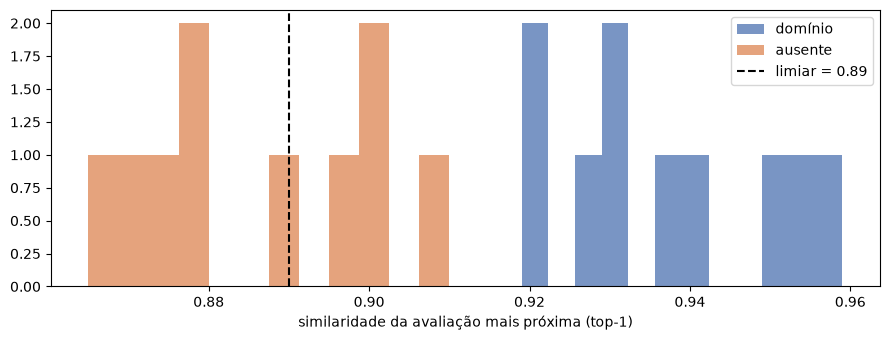

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for grupo, cor in [("domínio", "#4C72B0"), ("ausente", "#DD8452")]:
    ax.hist(calib.loc[calib.grupo == grupo, "top1"], bins=12, alpha=.75, label=grupo, color=cor)
ax.axvline(config.MIN_SIMILARITY, color="k", ls="--", label=f"limiar = {config.MIN_SIMILARITY}")
ax.set_xlabel("similaridade da avaliação mais próxima (top-1)"); ax.legend(); plt.tight_layout()
calib.groupby("grupo")[["n≥0.88", "n≥0.89", "n≥0.9"]].agg(["min", "median", "max"])

Com **limiar 0,89** e exigência de **pelo menos 5 evidências**, todos os temas do domínio passam com folga
(dezenas a centenas de avaliações), enquanto quase todos os temas ausentes ficam com 0–5. Os poucos casos que ainda
passam (ex.: “a França é linda” → “cortinas lindas”) são barrados pelas outras guardas: a análise de escopo e a
verificação de suficiência feita pelo LLM — por isso a proteção é **em camadas**.

## 4. Seleção dos conteúdos mais relevantes

Três filtros em sequência:

1. **Limiar de similaridade** (`MIN_SIMILARITY`): remove avaliações pouco relacionadas.
2. **Deduplicação de textos idênticos**: “Não recebi o produto” pode aparecer dezenas de vezes; mantemos um
   representante e informamos ao LLM quantas vezes ele ocorreu.
3. **MMR (Maximal Marginal Relevance, λ = 0,7)**: escolhe as 15 avaliações equilibrando relevância e diversidade,
   para que o contexto cubra *vários aspectos* do tema e não 15 variações da mesma reclamação.

In [7]:
acima = fused[fused["similarity"] >= config.MIN_SIMILARITY]
dedup = retriever._dedup_texts(acima)
mmr = retriever._mmr(dedup, config.FINAL_TOP_K, config.MMR_LAMBDA)
top_puro = dedup.head(config.FINAL_TOP_K)
print(f"{len(fused)} candidatos -> {len(acima)} acima do limiar -> {len(dedup)} textos distintos -> {len(mmr)} selecionados (MMR)")

def redundancia(df):  # similaridade média entre pares de avaliações selecionadas
    e = np.vstack(df["embedding"].values); s = e @ e.T
    return s[np.triu_indices(len(e), 1)].mean()
print(f"Redundância média (top-15 só por similaridade): {redundancia(top_puro):.3f}")
print(f"Redundância média (top-15 com MMR):            {redundancia(mmr):.3f}")
mmr[["similarity", "identical_count", "text"]]

276 candidatos -> 216 acima do limiar -> 172 textos distintos -> 15 selecionados (MMR)
Redundância média (top-15 só por similaridade): 0.912
Redundância média (top-15 com MMR):            0.901


,similarity,identical_count,text
0,0.942454,1,Demorou demais pra entregar
1,0.939303,1,entrega atrasada. o prazo terminou e nao recebi meu produto
14,0.932086,1,MUITO BOM PRODUTO CHEGOU NO PRAZO.
76,0.924905,1,"Decepcionada com a compra. O produto foi entregue com atraso, o pior não foi isso, o mesmo chegou solto em uma caixa suja, tive que usar ""panos"" para limpar..."
11,0.933614,1,Atraso. Produto não chegou no prazo
2,0.937262,1,nao entregou produto no prazo
31,0.929299,1,Produto como descrito e chegou antes do prazo
12,0.933239,1,Tive atraso na entrega
85,0.923709,1,Pedido entregue errado. Fiz uma compra de um produto e recebi outro produto.
95,0.921173,1,estou desapontada com o atraso da entrega


## 5. Construção do contexto

O contexto enviado ao LLM tem duas partes:

* **Perfil do tema**: estimativa de quantas avaliações (entre as 1.000 mais próximas) passam do limiar, nota média,
  % de notas 1–2, % de atraso e categorias — permite falar de **recorrência** sem inventar números;
* **Avaliações numeradas** `[R1]…[R15]` com metadados (nota, categoria, data, atraso), que o modelo usa para citar.

In [8]:
resultado = retriever.retrieve(consultas)
contexto = build_context(resultado)
print(contexto)

# Perfil das avaliações relacionadas ao tema (estimativa a partir da busca semântica)
- Avaliações semanticamente relacionadas: pelo menos 2224
- Nota média dessas avaliações: 2.58
- % com nota 1 ou 2: 54.9%
- % de pedidos entregues após o prazo (entre os entregues): 22.1%
- Categorias mais frequentes: {'beleza_saude': 212, 'cama_mesa_banho': 184, 'esporte_lazer': 167, 'informatica_acessorios': 162, 'moveis_decoracao': 155}

# Avaliações recuperadas (use os IDs para citar)
[R1] (nota 3/5; categoria: bebes; data: 2018-01; entregue 2 dias após o prazo) "Demorou demais pra entregar"
[R2] (nota 1/5; categoria: informatica_acessorios; data: 2018-06; entregue 7 dias após o prazo) "entrega atrasada. o prazo terminou e nao recebi meu produto"
[R3] (nota 5/5; categoria: perfumaria; data: 2017-06; entregue no prazo) "MUITO BOM PRODUTO CHEGOU NO PRAZO."
[R4] (nota 1/5; categoria: esporte_lazer; data: 2018-08; entregue 1 dias após o prazo) "Decepcionada com a compra. O produto foi entregue com atr

## 6. Geração da resposta

O Gemini recebe instruções de sistema rígidas (usar **apenas** o contexto, citar `[R#]` em cada afirmação, não
inventar números, declarar quando as evidências são insuficientes) e responde em **JSON estruturado**:
`sufficient_evidence`, `answer` e `limitations`. A temperatura baixa (0,1) reduz variações e “criatividade”.

In [9]:
gerada = llm.generate_answer(PERGUNTA, contexto)
print("sufficient_evidence:", gerada.sufficient_evidence)
print("limitations:", gerada.limitations)

sufficient_evidence: True
limitations: A análise baseia-se em uma amostra recuperada de 15 avaliações detalhadas e nas estatísticas de um perfil de aproximadamente 2224 avaliações relacionadas. A amostragem foca majoritariamente em insatisfações e problemas de entrega, o que pode representar um viés negativo e não refletir a totalidade das operações da base de clientes.


## 7. Validação e resposta final

`VoCRAG.ask()` executa todas as etapas acima e aplica três guardas:

| Guarda | Quando atua | Resultado |
|---|---|---|
| Escopo | LLM classifica a pergunta como fora do domínio | `fora_do_escopo`, sem busca nem geração |
| Evidência mínima | menos de `MIN_EVIDENCES` avaliações acima do limiar | `sem_evidencias`, sem chamar o LLM |
| Fundamentação | LLM declara evidência insuficiente **ou** a resposta não tem citações válidas | `evidencias_insuficientes` |

Além disso, as citações são **validadas**: IDs inexistentes são descartados e reportados.

In [10]:
resp = rag.ask(PERGUNTA)
show(resp)

### ❓ O que os clientes relatam sobre problemas relacionados à entrega?

**Status:** ✅ Respondida com evidências

**Consultas usadas na busca:** `O que os clientes relatam sobre problemas relacionados à entrega?` · `o produto atrasou muito além do prazo estipulado` · `a transportadora não entregou e o pacote sumiu` · `recebi o produto com muita demora e sem suporte`

**Perfil do tema:** ≥1547 avaliações relacionadas · nota média 2.56 · 56.4% com nota 1-2

**Modelo de geração:** `gemini-3.5-flash-lite`

---

Com base na amostra de pelo menos 1547 avaliações relacionadas (onde 56,4% possuem nota 1 ou 2 e 26,6% dos pedidos entregues apresentam atraso), os clientes relatam os seguintes problemas relacionados à entrega:

- **Atraso na entrega e não recebimento**: Os clientes frequentemente apontam demora excessiva, produtos que chegam dias após o prazo (como 3 a 21 dias de atraso), ou relatos de que o produto ainda não foi recebido mesmo após o prazo finalizado [R3, R4, R6, R7, R9, R13]. Há também casos em que o pedido consta como entregue no sistema, mas o cliente afirma não ter recebido [R2].
- **Demora no envio e despacho**: Clientes relatam lentidão para o envio do produto pela loja, levando mais de 20 dias para o despacho [R8].
- **Suporte ineficiente**: Relata-se dificuldade de comunicação, com ausência de atendimento humano (apenas robô) e prazos longos de resposta, além de mensagens ignoradas ao questionar sobre a demora [R2, R8].


> **Limitações:** A resposta baseia-se em uma amostra recuperada de 15 avaliações detalhadas e em estimativas agregadas de um universo de pelo menos 1547 avaliações. As categorias e sentimentos refletem apenas este recorte e podem não abranger todas as nuances do universo total de clientes.

**Evidências citadas (8):**

ref,similaridade,nota,categoria,data,atraso_dias,texto_identico_x,avaliacao
R2,0.914800,1,automotivo,2018-02,-13.000000,1,"Péssimo. produto consta como entregue e não recebi o produto.Não existe um tel. p/ falar com um atendente só um robô do outro lado da linha,48 horas úteis p/ uma resposta é muita coisa ."
R3,0.922300,1,utilidades_domesticas,2018-03,13.000000,1,ta demorando a entrega nao resebi minha compra ainda
R4,0.925800,4,ferramentas_jardim,2018-04,21.000000,1,Produto está atrasado
R6,0.919200,1,cama_mesa_banho,2018-02,nan,1,Pessimo muita demora na entrega
R7,0.909400,1,cama_mesa_banho,2018-03,3.000000,1,comprei o produto há tempos e ainda não recebi. muito demorado.
R8,0.915500,1,consoles_games,2018-02,-2.000000,1,"Demora para enviar o produto, levou mais de 20 dias e quando foi enviado mensagem perguntando sobre o motivo na demora para despachar fui sumariamente ignorado. O produto, apesar disso, veio certinho."
R9,0.917200,1,beleza_saude,2018-03,13.000000,1,Produto nao recebido Favor enviar informação urgente
R13,0.916200,1,cama_mesa_banho,2018-04,3.000000,1,O prazo de entrega finalizou e nao recebi o produto
